# Auditoria dos dados

Verificações de integridade, esquema, qualidade e distribuição do arquivo `data/raw/creditcard.csv`. Manifesto e procedência em `docs/02_dados.md`.

In [1]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
ARQUIVO = RAIZ / "data" / "raw" / "creditcard.csv"
SHA256_ESPERADO = "76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89"

COLUNAS_ESPERADAS = ["Time", *[f"V{i}" for i in range(1, 29)], "Amount", "Class"]
FEATURES = [c for c in COLUNAS_ESPERADAS if c != "Class"]

## Integridade

In [2]:
sha256 = hashlib.sha256(ARQUIVO.read_bytes()).hexdigest()
assert sha256 == SHA256_ESPERADO, f"SHA-256 divergente: {sha256}"
sha256

'76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89'

In [3]:
df = pd.read_csv(ARQUIVO)
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 1. Dimensões

In [4]:
print(f"Linhas: {df.shape[0]:,}  |  Colunas: {df.shape[1]}")

Linhas: 284,807  |  Colunas: 31


## 2. Esquema

In [5]:
colunas = list(df.columns)
print("Esquema idêntico ao esperado (nomes e ordem):", colunas == COLUNAS_ESPERADAS)
print("Faltando:", sorted(set(COLUNAS_ESPERADAS) - set(colunas)))
print("Extras:", sorted(set(colunas) - set(COLUNAS_ESPERADAS)))

Esquema idêntico ao esperado (nomes e ordem): True
Faltando: []
Extras: []


## 3. Tipos

In [6]:
print(df.dtypes.value_counts(), end="\n\n")
print("Todas numéricas:", all(pd.api.types.is_numeric_dtype(t) for t in df.dtypes))
print("Tipo de Class:", df["Class"].dtype)

float64    30
int64       1
Name: count, dtype: int64

Todas numéricas: True
Tipo de Class: int64


## 4. Valores ausentes

In [7]:
ausentes = df.isna().sum()
print("Total de valores ausentes:", int(ausentes.sum()))
ausentes[ausentes > 0]

Total de valores ausentes: 0


Series([], dtype: int64)

## 5. Valores não finitos

In [8]:
infinitos = np.isinf(df.to_numpy()).sum(axis=0)
print("Total de valores infinitos:", int(infinitos.sum()))

Total de valores infinitos: 0


## 6–7. Rótulos e prevalência

In [9]:
print("Valores distintos de Class:", sorted(df["Class"].unique().tolist()))

classes = pd.DataFrame(
    {
        "contagem": df["Class"].value_counts().sort_index(),
        "percentual": (df["Class"].value_counts(normalize=True).sort_index() * 100).round(4),
    }
)
classes

Valores distintos de Class: [0, 1]


,contagem,percentual
Class,,
0,284315,99.8273
1,492,0.1727


## 8. Duplicatas exatas

In [10]:
dup_envolvidas = df.duplicated(keep=False)
dup_excedentes = df.duplicated(keep="first")

print("Linhas envolvidas em duplicação:", int(dup_envolvidas.sum()))
print("Cópias excedentes (removíveis mantendo uma):", int(dup_excedentes.sum()))
print("Cópias excedentes que são fraude:", int(df.loc[dup_excedentes, "Class"].sum()))
print("Fraudes distintas após remover excedentes:", int(df.loc[~dup_excedentes, "Class"].sum()))

Linhas envolvidas em duplicação: 1854
Cópias excedentes (removíveis mantendo uma): 1081
Cópias excedentes que são fraude: 19
Fraudes distintas após remover excedentes: 473


## 9. Mesmas features com rótulos diferentes

In [11]:
mesmas_features = df[df.duplicated(subset=FEATURES, keep=False)]
rotulos_por_grupo = mesmas_features.groupby(FEATURES)["Class"].nunique()
grupos_conflitantes = rotulos_por_grupo[rotulos_por_grupo > 1]

print("Grupos com features idênticas e Class divergente:", len(grupos_conflitantes))

Grupos com features idênticas e Class divergente: 0


## 10. Intervalo de `Time`

In [12]:
tempo_horas = df["Time"].agg(["min", "max"]) / 3600
print(f"Time: {tempo_horas['min']:.2f} h a {tempo_horas['max']:.2f} h")

Time: 0.00 h a 48.00 h


## 11. Distribuição de `Amount`

In [13]:
print("Transações com Amount = 0:", int((df["Amount"] == 0).sum()))
print("Amount negativo:", int((df["Amount"] < 0).sum()))
df["Amount"].describe()

Transações com Amount = 0: 1825
Amount negativo: 0


count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64

## 12. `Amount` por classe

In [14]:
amount_por_classe = df.groupby("Class")["Amount"].describe()
amount_por_classe["zeros"] = df["Amount"].eq(0).groupby(df["Class"]).sum()
amount_por_classe

,count,mean,std,min,25%,50%,75%,max,zeros
Class,,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16,1798
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87,27


## Distribuições

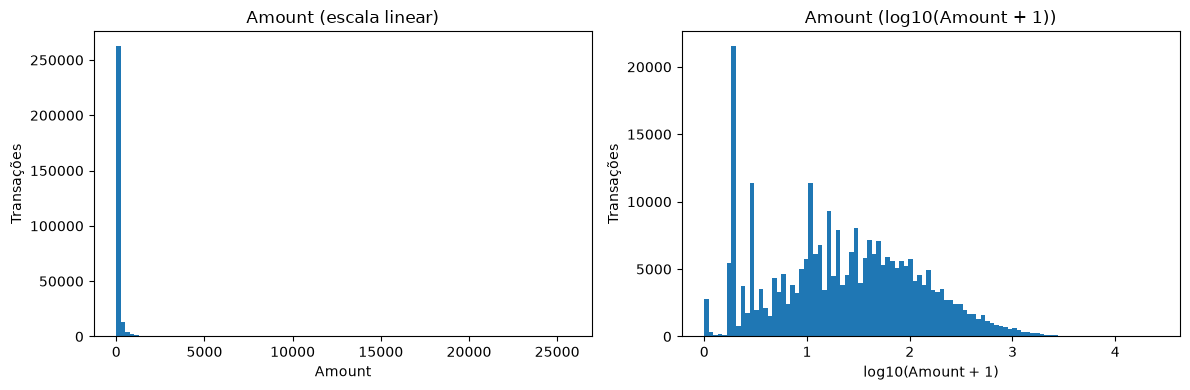

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.hist(df["Amount"], bins=100)
ax1.set(title="Amount (escala linear)", xlabel="Amount", ylabel="Transações")
ax2.hist(np.log10(df["Amount"] + 1), bins=100)
ax2.set(title="Amount (log10(Amount + 1))", xlabel="log10(Amount + 1)", ylabel="Transações")
plt.tight_layout()

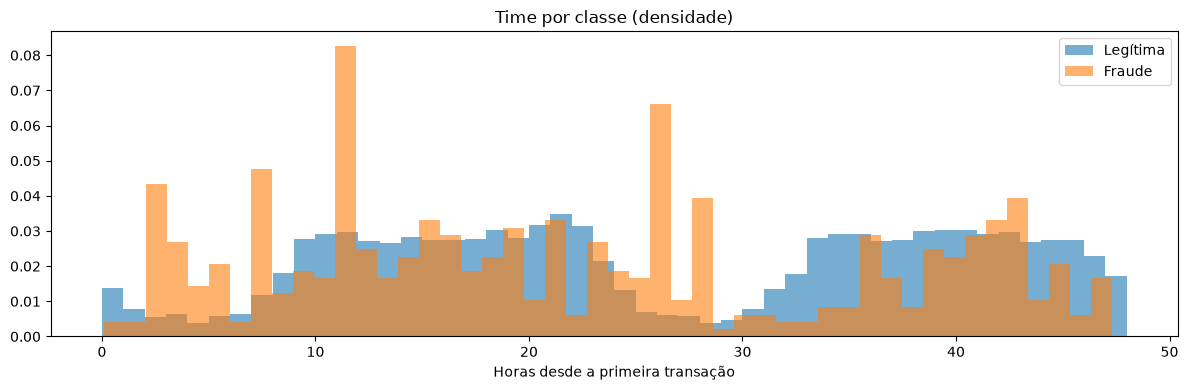

In [16]:
fig, ax = plt.subplots(figsize=(12, 4))
for classe, rotulo in [(0, "Legítima"), (1, "Fraude")]:
    horas = df.loc[df["Class"] == classe, "Time"] / 3600
    ax.hist(horas, bins=48, density=True, alpha=0.6, label=rotulo)
ax.set(title="Time por classe (densidade)", xlabel="Horas desde a primeira transação")
ax.legend()
plt.tight_layout()

## 13. Repetição de `V1`–`V28` e `Amount` com `Time` diferente

In [17]:
SEM_TIME = [c for c in FEATURES if c != "Time"]
repetidas_sem_time = df.duplicated(subset=SEM_TIME) & ~df.duplicated()

print(
    "Linhas que repetem V1–V28 e Amount de outra linha, com Time diferente:",
    int(repetidas_sem_time.sum()),
)
print("Dessas, fraudes:", int(df.loc[repetidas_sem_time, "Class"].sum()))

Linhas que repetem V1–V28 e Amount de outra linha, com Time diferente: 8063
Dessas, fraudes: 0


## Resumo após remoção das duplicatas exatas

In [18]:
df_dedup = df.drop_duplicates(keep="first")
zeros = df_dedup["Amount"].eq(0)

resumo = pd.Series(
    {
        "linhas": len(df_dedup),
        "fraudes": int(df_dedup["Class"].sum()),
        "prevalencia_%": round(df_dedup["Class"].mean() * 100, 4),
        "amount_zero": int(zeros.sum()),
        "fraudes_amount_zero": int(df_dedup.loc[zeros, "Class"].sum()),
        "taxa_fraude_amount_zero_%": round(df_dedup.loc[zeros, "Class"].mean() * 100, 2),
        "mediana_amount_legitima": df_dedup.loc[df_dedup["Class"] == 0, "Amount"].median(),
        "mediana_amount_fraude": df_dedup.loc[df_dedup["Class"] == 1, "Amount"].median(),
    }
)
resumo

linhas                       283726.0000
fraudes                         473.0000
prevalencia_%                     0.1667
amount_zero                    1808.0000
fraudes_amount_zero              25.0000
taxa_fraude_amount_zero_%         1.3800
mediana_amount_legitima          22.0000
mediana_amount_fraude             9.8200
dtype: float64

In [19]:
intervalos = df_dedup[FEATURES].agg(["min", "max"]).T
intervalos.loc[["Time", "Amount"]]

,min,max
Time,0.0,172792.00
Amount,0.0,25691.16


In [20]:
V = [f"V{i}" for i in range(1, 29)]
print(f"V1–V28: mínimo {df_dedup[V].min().min():.4f}, máximo {df_dedup[V].max().max():.4f}")

V1–V28: mínimo -113.7433, máximo 120.5895
